# Laboratorio 13: Clustering de textos

**Estudiante:** Angela Jara · **Curso:** Software Inteligente

**Objetivo:** agrupar noticias de la BBC sin usar sus etiquetas, comparar tres algoritmos de clustering con tres métricas internas y declarar el mejor modelo.

## 1. Configuración

In [1]:
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import Normalizer

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

In [2]:
SEED = 42
DATA_URL = "http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip"
DATA_DIR = Path("data")
TFIDF = dict(stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True)
N_COMPONENTS = 10                      # dimensiones LSA (ver sección 3)
K_RANGE = range(2, 11)                 # k candidatos para K-Means y Ward
EPS_GRID = np.arange(0.15, 1.0, 0.025)
MIN_SAMPLES_GRID = (5, 10, 15, 20, 30)
MAX_NOISE = 0.30                       # DBSCAN no puede descartar más del 30 % de documentos

In [3]:
def metricas(X, labels):
    """Silhouette, Calinski-Harabasz y Davies-Bouldin sobre todos los documentos.

    El ruido de DBSCAN (-1) cuenta como un grupo más: así no se premia descartar datos.
    """
    n_clusters = len(set(labels) - {-1})
    if n_clusters < 2:
        return dict(silhouette=np.nan, calinski_harabasz=np.nan, davies_bouldin=np.nan)
    return dict(
        silhouette=silhouette_score(X, labels),
        calinski_harabasz=calinski_harabasz_score(X, labels),
        davies_bouldin=davies_bouldin_score(X, labels),
    )

## 2. Datos

**BBC News** (Greene y Cunningham, 2006): 2 225 noticias en inglés de 2004–2005 en 5 temas. Los derechos de los textos son de la BBC, por eso se descargan al ejecutar y no se incluyen en el repositorio.

In [4]:
zip_path = DATA_DIR / "bbc-fulltext.zip"
if not (DATA_DIR / "bbc").exists():
    DATA_DIR.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(DATA_URL, zip_path)
    except OSError as e:
        raise RuntimeError(f"No se pudo descargar {DATA_URL}: {e}") from e
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

def leer(f):
    # La mayoría es UTF-8, pero algunos archivos usan Latin-1 (p. ej. «£»).
    try:
        return f.read_bytes().decode("utf-8")
    except UnicodeDecodeError:
        return f.read_bytes().decode("latin-1")

filas = [(leer(f), carpeta.name)
         for carpeta in sorted(p for p in (DATA_DIR / "bbc").iterdir() if p.is_dir())
         for f in sorted(carpeta.glob("*.txt"))]
df = pd.DataFrame(filas, columns=["texto", "tema"]).astype({"tema": "category"})
assert len(df) == 2225 and df.tema.nunique() == 5
df.tema.value_counts().sort_index().to_frame("documentos").T

tema,business,entertainment,politics,sport,tech
documentos,510,386,417,511,401


Limpieza:
- minúsculas y espacios normalizados;
- se eliminan artículos vacíos y duplicados;
- las *stop words* se quitan al vectorizar; el titular se conserva como texto.

In [5]:
df["texto_limpio"] = df.texto.str.lower().str.split().str.join(" ")
vacios = (df.texto_limpio == "").sum()
df = df[df.texto_limpio != ""]
n_antes = len(df)
df = df.drop_duplicates("texto_limpio").reset_index(drop=True)
print(f"Vacíos eliminados: {vacios} · duplicados eliminados: {n_antes - len(df)} · quedan: {len(df)}")
assert len(df) == 2124

print("\nANTES:  ", df.texto[0][:300].replace("\n", " "))
print("DESPUÉS:", df.texto_limpio[0][:300])

Vacíos eliminados: 0 · duplicados eliminados: 101 · quedan: 2124

ANTES:   Ad sales boost Time Warner profit  Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and highe
DESPUÉS: ad sales boost time warner profit quarterly profits at us media giant timewarner jumped 76% to $1.13bn (£600m) for the three months to december, from $639m year-earlier. the firm, which is now one of the biggest investors in google, benefited from sales of high-speed internet connections and higher 


## 3. Representación

TF-IDF resalta las palabras propias de cada noticia; LSA (SVD truncada) la reduce a 10 dimensiones densas, porque DBSCAN pierde la noción de densidad en alta dimensión. Tras normalizar cada vector a norma 1, la distancia euclidiana equivale a la distancia coseno.

In [6]:
tfidf = TfidfVectorizer(**TFIDF)
X_tfidf = tfidf.fit_transform(df.texto_limpio)
svd = TruncatedSVD(N_COMPONENTS, random_state=SEED)
X = Normalizer().fit_transform(svd.fit_transform(X_tfidf))

print(f"TF-IDF: {X_tfidf.shape[0]} documentos × {X_tfidf.shape[1]} términos")
print(f"LSA: {X.shape}, varianza TF-IDF conservada: {svd.explained_variance_ratio_.sum():.1%}")
assert X.shape == (2124, 10) and np.allclose(np.linalg.norm(X, axis=1), 1)

TF-IDF: 2124 documentos × 8848 términos
LSA: (2124, 10), varianza TF-IDF conservada: 5.9%


## 4. Algoritmos de clustering

Se usa un algoritmo de cada familia: particional (K-Means), jerárquico (Ward) y de densidad (DBSCAN). Los hiperparámetros se eligen sin etiquetas, con el **mayor Silhouette**; Calinski-Harabasz se muestra pero no decide, porque baja casi siempre al subir *k*.

In [7]:
MODELOS = {}

def buscar_k(fabrica, nombre):
    """Ajusta fabrica(k) para cada k, grafica las 3 métricas y devuelve el k de mayor Silhouette."""
    busqueda = pd.DataFrame([{"k": k, **metricas(X, fabrica(k).fit_predict(X))} for k in K_RANGE]).set_index("k")
    k_mejor = int(busqueda.silhouette.idxmax())
    fig, axs = plt.subplots(1, 3, figsize=(11, 2.6))
    for ax, col in zip(axs, busqueda.columns):
        ax.plot(busqueda.index, busqueda[col], "o-")
        ax.axvline(k_mejor, color="red", ls="--")
        ax.set(title=col, xlabel="k")
    fig.suptitle(f"{nombre}: búsqueda de k (rojo = elegido)")
    fig.tight_layout()
    plt.show()
    return k_mejor, busqueda

def registrar(nombre, params, labels, busqueda):
    MODELOS[nombre] = dict(nombre=nombre, params=params, labels=labels,
                           n_clusters=len(set(labels) - {-1}),
                           ruido=float(np.mean(labels == -1)), busqueda=busqueda)
    print(f"{nombre} {params} → tamaños:", {int(c): int(n) for c, n in zip(*np.unique(labels, return_counts=True))})

### 4.1 K-Means

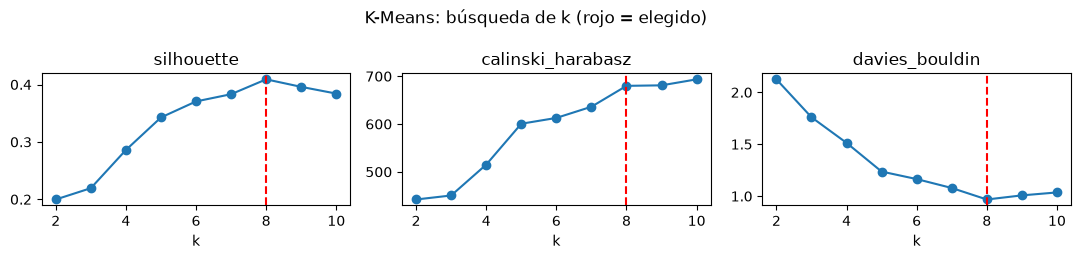

K-Means {'k': 8} → tamaños: {0: 200, 1: 186, 2: 361, 3: 289, 4: 418, 5: 182, 6: 350, 7: 138}


In [8]:
def kmeans(k):
    return KMeans(k, n_init=10, random_state=SEED)

k, busq = buscar_k(kmeans, "K-Means")
registrar("K-Means", {"k": k}, kmeans(k).fit_predict(X), busq)

### 4.2 Aglomerativo Ward

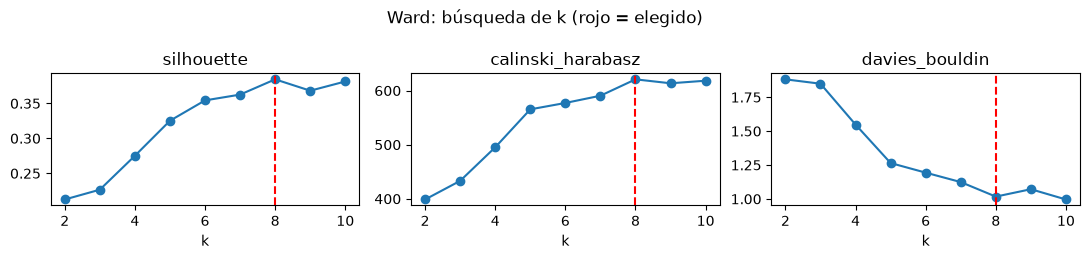

Ward {'k': 8} → tamaños: {0: 380, 1: 432, 2: 182, 3: 197, 4: 311, 5: 303, 6: 197, 7: 122}


In [9]:
def ward(k):
    return AgglomerativeClustering(k, linkage="ward")

k, busq = buscar_k(ward, "Ward")
registrar("Ward", {"k": k}, ward(k).fit_predict(X), busq)

### 4.3 DBSCAN

El gráfico de *k*-distancias ordena la distancia de cada documento a su 10.º vecino; el codo indica la zona útil de `eps`. Luego se prueba una rejilla `eps × min_samples` y solo valen configuraciones con ≥ 2 clusters y ≤ 30 % de ruido.

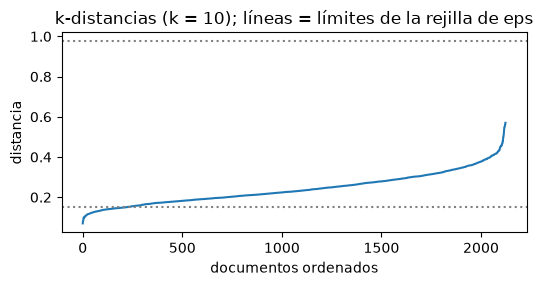

In [10]:
# n_neighbors=11 porque el vecino 0 es el propio punto.
dist = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X)[0][:, -1]
plt.figure(figsize=(6, 2.6))
plt.plot(np.sort(dist))
for e in (EPS_GRID.min(), EPS_GRID.max()):
    plt.axhline(e, color="grey", ls=":")
plt.title("k-distancias (k = 10); líneas = límites de la rejilla de eps")
plt.xlabel("documentos ordenados"); plt.ylabel("distancia")
plt.show()

In [11]:
filas = []
for eps in EPS_GRID:
    for ms in MIN_SAMPLES_GRID:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        filas.append({"eps": round(eps, 3), "min_samples": ms, "n_clusters": len(set(l) - {-1}),
                      "ruido": np.mean(l == -1), **metricas(X, l)})
busq = pd.DataFrame(filas)
validas = busq[(busq.n_clusters >= 2) & (busq.ruido <= MAX_NOISE)].sort_values("silhouette", ascending=False)
print(f"Configuraciones válidas: {len(validas)} de {len(busq)}")
display(validas.head(5))

if len(validas):
    mejor = validas.iloc[0]
    params = {"eps": float(mejor.eps), "min_samples": int(mejor.min_samples)}
    registrar("DBSCAN", params, DBSCAN(**params).fit_predict(X), busq)
    print(f"Ruido: {MODELOS['DBSCAN']['ruido']:.1%}")
else:
    print("Ninguna configuración cumple ≥2 clusters y ≤30 % de ruido: DBSCAN queda inválido.")
    registrar("DBSCAN", {}, np.full(len(X), -1), busq)

Configuraciones válidas: 26 de 170


,eps,min_samples,n_clusters,ruido,silhouette,calinski_harabasz,davies_bouldin
39,0.325,30,8,0.129,0.365,495.589,1.442
33,0.300,20,9,0.125,0.360,473.893,1.293
27,0.275,15,10,0.164,0.333,436.796,1.226
34,0.300,30,9,0.205,0.325,441.898,1.354
28,0.275,20,11,0.202,0.315,411.989,1.198


DBSCAN {'eps': 0.325, 'min_samples': 30} → tamaños: {-1: 274, 0: 426, 1: 386, 2: 296, 3: 293, 4: 61, 5: 174, 6: 133, 7: 81}
Ruido: 12.9%


## 5. Visualización

Una sola proyección t-SNE de `X`, común a los tres modelos para poder compararlos; solo sirve para visualizar y no se usa en las métricas. El ruido de DBSCAN aparece en gris.

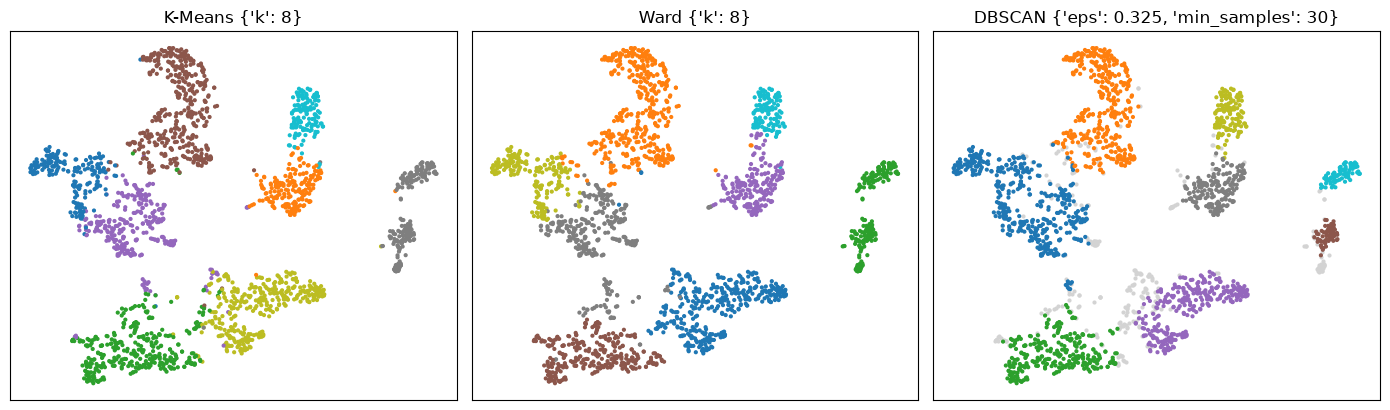

In [12]:
X_2d = TSNE(2, init="pca", random_state=SEED).fit_transform(X)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, m in zip(axs, MODELOS.values()):
    l = m["labels"]
    ax.scatter(*X_2d[l == -1].T, s=4, c="lightgrey", label="ruido")
    ax.scatter(*X_2d[l != -1].T, s=4, c=l[l != -1], cmap="tab10")
    ax.set(title=f"{m['nombre']} {m['params']}", xticks=[], yticks=[])
fig.tight_layout()
plt.show()

## 6. Evaluación y mejor modelo

| Métrica | Qué mide | Mejor si |
|---|---|---|
| Silhouette | cohesión frente a separación de cada punto, en [−1, 1] | ↑ |
| Calinski-Harabasz | dispersión entre clusters / dentro de clusters | ↑ |
| Davies-Bouldin | similitud media de cada cluster con el más parecido | ↓ |

**Regla:** se ordena a los modelos en cada métrica (1 = mejor) y gana el menor rango medio; un empate lo decide Silhouette. El ruido de DBSCAN cuenta como un grupo más.

In [13]:
tabla = pd.DataFrame({n: {**metricas(X, m["labels"]), "n_clusters": m["n_clusters"], "ruido": m["ruido"]}
                      for n, m in MODELOS.items()}).T.astype(float)
tabla["rank_sil"] = tabla.silhouette.rank(ascending=False, method="min")
tabla["rank_ch"] = tabla.calinski_harabasz.rank(ascending=False, method="min")
tabla["rank_db"] = tabla.davies_bouldin.rank(ascending=True, method="min")
tabla["rank_medio"] = tabla[["rank_sil", "rank_ch", "rank_db"]].mean(axis=1)  # NaN = modelo inválido
tabla.round(3)

,silhouette,calinski_harabasz,davies_bouldin,n_clusters,ruido,rank_sil,rank_ch,rank_db,rank_medio
K-Means,0.409,679.912,0.968,8.0,0.000,1.0,1.0,1.0,1.0
Ward,0.384,620.833,1.017,8.0,0.000,2.0,2.0,2.0,2.0
DBSCAN,0.365,495.589,1.442,8.0,0.129,3.0,3.0,3.0,3.0


In [14]:
ganador = tabla.dropna(subset=["rank_medio"]).sort_values(["rank_medio", "silhouette"],
                                                          ascending=[True, False]).index[0]
print(f"Mejor modelo: {ganador} {MODELOS[ganador]['params']}")

mejores = {"Silhouette": tabla.silhouette.idxmax(), "Calinski-Harabasz": tabla.calinski_harabasz.idxmax(),
           "Davies-Bouldin": tabla.davies_bouldin.idxmin()}
if len(set(mejores.values())) > 1:
    print("Las métricas no coinciden:", mejores)
else:
    print("Las tres métricas coinciden.")

Mejor modelo: K-Means {'k': 8}
Las tres métricas coinciden.


K-Means (*k* = 8) es primero en las tres métricas (Silhouette 0,409; Calinski-Harabasz 680; Davies-Bouldin 0,97), así que la regla no tuvo que resolver desacuerdos. Ward queda cerca con el mismo *k*; DBSCAN es último porque su 12,9 % de ruido forma un grupo poco cohesionado.

## 7. Interpretación

Términos con mayor peso TF-IDF medio en cada cluster del modelo ganador.

In [15]:
labels_ganador = MODELOS[ganador]["labels"]
terminos = tfidf.get_feature_names_out()
top = {}
for c in sorted(set(labels_ganador)):
    peso = np.asarray(X_tfidf[labels_ganador == c].mean(axis=0)).ravel()
    top["ruido" if c == -1 else c] = ", ".join(terminos[np.argsort(peso)[::-1][:10]])
pd.Series(top, name="top 10 términos").to_frame()

,top 10 términos
0,"growth, economy, economic, prices, 2004, rise, bank, rate, market, figures"
1,"club, chelsea, league, arsenal, cup, game, manager, season, boss, team"
2,"people, technology, users, use, mobile, software, digital, computer, net, online"
3,"company, firm, shares, deal, market, mr, financial, chief, group, executive"
4,"mr, labour, election, government, party, blair, minister, people, tory, secretary"
5,"champion, olympic, world, open, final, win, seed, won, australian, championships"
6,"film, best, awards, award, star, music, actor, films, band, tv"
7,"england, rugby, nations, ireland, wales, game, coach, france, robinson, scotland"


**Solo referencia:** las categorías no se usaron para entrenar, ajustar ni elegir el modelo.

In [16]:
pd.crosstab(labels_ganador, df.tema, rownames=["cluster"], colnames=["tema"])

tema,business,entertainment,politics,sport,tech
cluster,,,,,
0,198,1,1,0,0
1,2,0,0,183,1
2,15,14,5,0,327
3,270,10,3,0,6
4,18,5,394,0,1
5,0,0,0,181,1
6,0,339,0,0,11
7,0,0,0,138,0


Los clusters son temáticos: deporte se divide en fútbol (1), atletismo y tenis (5) y rugby (7), y negocios en economía (0) y empresas (3). Política, tecnología y entretenimiento quedan casi puros en un cluster cada uno.

## 8. Conclusión

El mejor modelo es **K-Means con *k* = 8**: gana en Silhouette (0,409), Calinski-Harabasz (680) y Davies-Bouldin (0,97). Ward obtiene valores parecidos, mientras que DBSCAN queda último al dejar el 12,9 % de las noticias como ruido. Sin usar etiquetas, los clusters recuperan los 5 temas de la BBC y separan subtemas coherentes. Limitación: LSA con 10 dimensiones conserva solo el 5,9 % de la varianza TF-IDF, y Silhouette prefirió *k* = 8 en vez de los 5 temas originales.

## 9. Referencias

- Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics*, 3(1), 1–27.
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE TPAMI*, 1(2), 224–227.
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proc. KDD*, 226–231.
- Greene, D., & Cunningham, P. (2006). Practical solutions to the problem of diagonal dominance in kernel document clustering. *Proc. ICML*, 377–384.
- Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Trans. Information Theory*, 28(2), 129–137.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *J. Comput. Appl. Math.*, 20, 53–65.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *JASA*, 58(301), 236–244.